# Un singolo neurone



## Preparazione in Colab

1. Salvare una copia del notebook nel proprio Drive.
2. Eseguire la cella seguente e attendere «Preparazione completata».
3. Eseguire le celle nell’ordine e svolgere gli esercizi.

La cella di preparazione acquisisce i dataset e i controlli degli esercizi dal repository del corso e configura l’ambiente Python. Dopo il riavvio della sessione occorre eseguire nuovamente la preparazione.

In [ ]:
from pathlib import Path
import hashlib
import importlib.util
from urllib.request import urlopen
from IPython.display import display, Markdown

course_source = 'https://raw.githubusercontent.com/prof-davidaffo/kaggle-learntools/master'
course_root = (Path("/content") if Path("/content").is_dir() else Path.home()) / "ai-lab-colab"
course_root.mkdir(parents=True, exist_ok=True)
bootstrap_path = course_root / "_bootstrap.py"
bootstrap_hash = '56f1300be5bf273a70dd4a30e704b20f642ec01dacc4d2d4b5a295a02e1da60f'
if not bootstrap_path.is_file() or hashlib.sha256(bootstrap_path.read_bytes()).hexdigest() != bootstrap_hash:
    with urlopen(course_source + "/ai_lab/tools/colab_runtime.py", timeout=90) as response:
        bootstrap_data = response.read()
    if hashlib.sha256(bootstrap_data).hexdigest() != bootstrap_hash:
        raise RuntimeError("Course setup changed. Reopen the latest notebook from the course site.")
    bootstrap_path.write_bytes(bootstrap_data)
bootstrap_spec = importlib.util.spec_from_file_location("ai_lab_colab_bootstrap", bootstrap_path)
bootstrap = importlib.util.module_from_spec(bootstrap_spec)
bootstrap_spec.loader.exec_module(bootstrap)
bootstrap.download_runtime(course_source + "/ai_lab/colab/runtime.json", course_source, course_root)
bootstrap.setup(course_root, globals(), deep_learning=True)
display(Markdown("**Preparazione completata.** Puoi eseguire le celle della lezione."))


# Benvenuto nel deep learning!

Benvenuto al corso *Introduzione al Deep Learning* di Kaggle! Stai per imparare tutto ciò che serve per iniziare a costruire le tue reti neurali profonde. Usando Keras e TensorFlow imparerai a:

- creare un’architettura di rete neurale **completamente connessa**, o *fully-connected*;
- applicare le reti neurali a due problemi classici del machine learning: **regressione** e **classificazione**;
- addestrare le reti con la **discesa stocastica del gradiente**;
- migliorare le prestazioni con **dropout**, **batch normalization** e altre tecniche.

Le lezioni introdurranno questi argomenti con esempi interamente svolti. Negli esercizi li esplorerai più in profondità e li applicherai a dataset reali.

Cominciamo!

# Che cos’è il deep learning?

Alcuni dei progressi più impressionanti degli ultimi anni nell’intelligenza artificiale sono avvenuti nel campo del *deep learning*. Traduzione del linguaggio naturale, riconoscimento delle immagini e giochi sono tutti compiti nei quali i modelli di deep learning si sono avvicinati alle prestazioni umane o le hanno persino superate.

Ma che cos’è il deep learning? Il **deep learning** è un approccio al machine learning caratterizzato da sequenze profonde di calcoli sovrapposti. È questa profondità di calcolo che ha consentito ai modelli di distinguere gli schemi complessi e gerarchici presenti nei dataset reali più difficili.

Grazie alla loro potenza e scalabilità, le **reti neurali** sono diventate il modello caratteristico del deep learning. Sono composte da neuroni, ciascuno dei quali esegue soltanto un calcolo semplice. La potenza della rete deriva invece dalla complessità delle connessioni che questi neuroni possono formare.

# L’unità lineare

Cominciamo quindi dal componente fondamentale di una rete neurale: il singolo neurone. Un **neurone**, o **unità**, con un solo ingresso si rappresenta così:

<figure style="padding: 1em;">
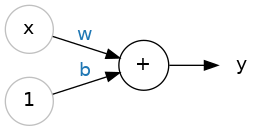
<figcaption><center>L’unità lineare: $y = w x + b$</center></figcaption>
</figure>

L’ingresso è `x`. La sua connessione con il neurone ha un **peso**, `w`. Ogni volta che un valore attraversa una connessione, lo moltiplichiamo per il peso della connessione. Per l’ingresso `x`, ciò che raggiunge il neurone è `w * x`. Una rete neurale «impara» modificando i propri pesi.

`b` è un tipo particolare di peso che chiamiamo **bias**. Al bias non è associato alcun dato in ingresso: nello schema mettiamo invece un `1`, così il valore che raggiunge il neurone è semplicemente `b`, dato che `1 * b = b`. Il bias consente al neurone di modificare l’uscita indipendentemente dagli ingressi.

`y` è il valore prodotto infine dal neurone. Per ottenere l’uscita, il neurone somma tutti i valori ricevuti attraverso le connessioni. L’attivazione di questo neurone è `y = w * x + b`, oppure, in formula, $y = w x + b$.

> **La formula $y = w x + b$ ti sembra familiare?**
>
> È l’equazione di una retta! È la forma con coefficiente angolare e intercetta: $w$ è il coefficiente angolare e $b$ è l’intercetta sull’asse y.


# Esempio: l’unità lineare come modello

Anche se i singoli neuroni operano normalmente come parte di una rete più grande, spesso è utile iniziare con un modello a un solo neurone come riferimento, o *baseline*. I modelli a un neurone sono modelli *lineari*.

Pensiamo a come potrebbe funzionare su un dataset come [80 Cereals](https://www.kaggle.com/crawford/80-cereals). Addestrando un modello con `'sugars'`, i grammi di zucchero per porzione, come ingresso e `'calories'`, le calorie per porzione, come uscita, potremmo trovare un bias `b=90` e un peso `w=2.5`. Potremmo stimare il contenuto calorico di un cereale con 5 grammi di zucchero per porzione in questo modo:

<figure style="padding: 1em;">
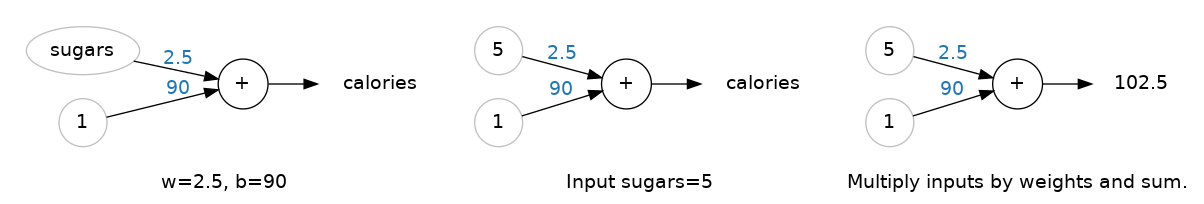
<figcaption><center>Calcolo con l’unità lineare.</center></figcaption>
</figure>

Verificando con la formula, otteniamo $calories = 2.5 \times 5 + 90 = 102.5$, proprio come previsto.

# Più ingressi

Il dataset *80 Cereals* contiene molte altre feature oltre a `'sugars'`. E se volessimo estendere il modello per includere, per esempio, il contenuto di fibre o proteine? È abbastanza semplice: aggiungiamo altre connessioni in ingresso al neurone, una per ogni feature aggiuntiva. Per trovare l’uscita, moltiplichiamo ciascun ingresso per il peso della sua connessione e sommiamo tutti i contributi.

<figure style="padding: 1em;">
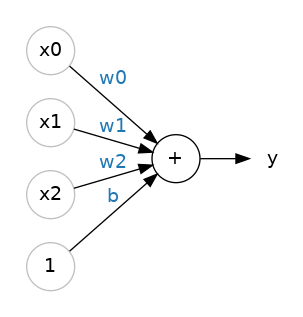
<figcaption><center>Un’unità lineare con tre ingressi.</center></figcaption>
</figure>

La formula di questo neurone sarebbe $y = w_0 x_0 + w_1 x_1 + w_2 x_2 + b$. Un’unità lineare con due ingressi si adatta a un piano; con più di due ingressi si adatta a un iperpiano.

# Unità lineari in Keras

Il modo più semplice per creare un modello in Keras è usare `keras.Sequential`, che costruisce una rete neurale come una sequenza di *layer*, cioè strati. Possiamo creare modelli come quelli appena visti usando uno strato *dense*, che approfondiremo nella prossima lezione.

Potremmo definire un modello lineare che accetta tre feature in ingresso, `'sugars'`, `'fiber'` e `'protein'`, e produce una sola uscita, `'calories'`, in questo modo:


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

# Crea una rete con una sola unità lineare.
model = keras.Sequential([
    layers.Dense(units=1, input_shape=[3])
])

Con il primo argomento, `units`, definiamo quante uscite vogliamo. In questo caso prevediamo soltanto `'calories'`, quindi useremo `units=1`.

Con il secondo argomento, `input_shape`, comunichiamo a Keras le dimensioni degli ingressi. Impostando `input_shape=[3]`, il modello accetterà tre feature in ingresso: `'sugars'`, `'fiber'` e `'protein'`.

Ora questo modello è pronto per essere addestrato sui dati di training!

> **Perché `input_shape` è una lista Python?**
>
> In questo corso useremo dati tabellari, come quelli di un DataFrame pandas. Avremo un ingresso per ogni feature del dataset. Le feature sono disposte per colonne, quindi avremo sempre `input_shape=[num_columns]`.
>
> Keras usa una lista per consentire anche dataset più complessi. Le immagini, per esempio, potrebbero richiedere tre dimensioni: `[height, width, channels]`, cioè altezza, larghezza e canali.

# Ora tocca a te

[**Definisci un modello lineare**](https://prof-davidaffo.github.io/kaggle-learntools/corsi/deep_learning_intro/ex1.html) per il dataset *Red Wine Quality*.
